# IMPORT

In [1]:
#202431140
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

# ANALISIS EDA

In [2]:
#202431140
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
#202431140
df = pd.read_csv('03_counter_strike_2.csv', sep=",") 
print("=== INFORMASI DATASET ===")
print(df.info())

=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   time_left     2000 non-null   float64
 1   ct_score      2000 non-null   float64
 2   t_score       2000 non-null   float64
 3   map           2000 non-null   object 
 4   bomb_planted  2000 non-null   bool   
 5   ct_health     2000 non-null   float64
 6   t_health      2000 non-null   float64
 7   ct_armor      2000 non-null   float64
 8   t_armor       2000 non-null   float64
 9   ct_money      2000 non-null   float64
 10  t_money       2000 non-null   float64
 11  ct_helmets    2000 non-null   float64
 12  t_helmets     2000 non-null   float64
 13  round_winner  2000 non-null   object 
dtypes: bool(1), float64(11), object(2)
memory usage: 205.2+ KB
None


# DECISION TREE

In [4]:
#202431140
le_map = LabelEncoder()
df['map'] = le_map.fit_transform(df['map']) 

le_target = LabelEncoder()
df['round_winner'] = le_target.fit_transform(df['round_winner']) 

df['bomb_planted'] = df['bomb_planted'].astype(int)

print("\n=== LABEL KELAS TARGET (round_winner) ===")
for i, label in enumerate(le_target.classes_):
    print(f"{i} = {label}")


=== LABEL KELAS TARGET (round_winner) ===
0 = CT
1 = T


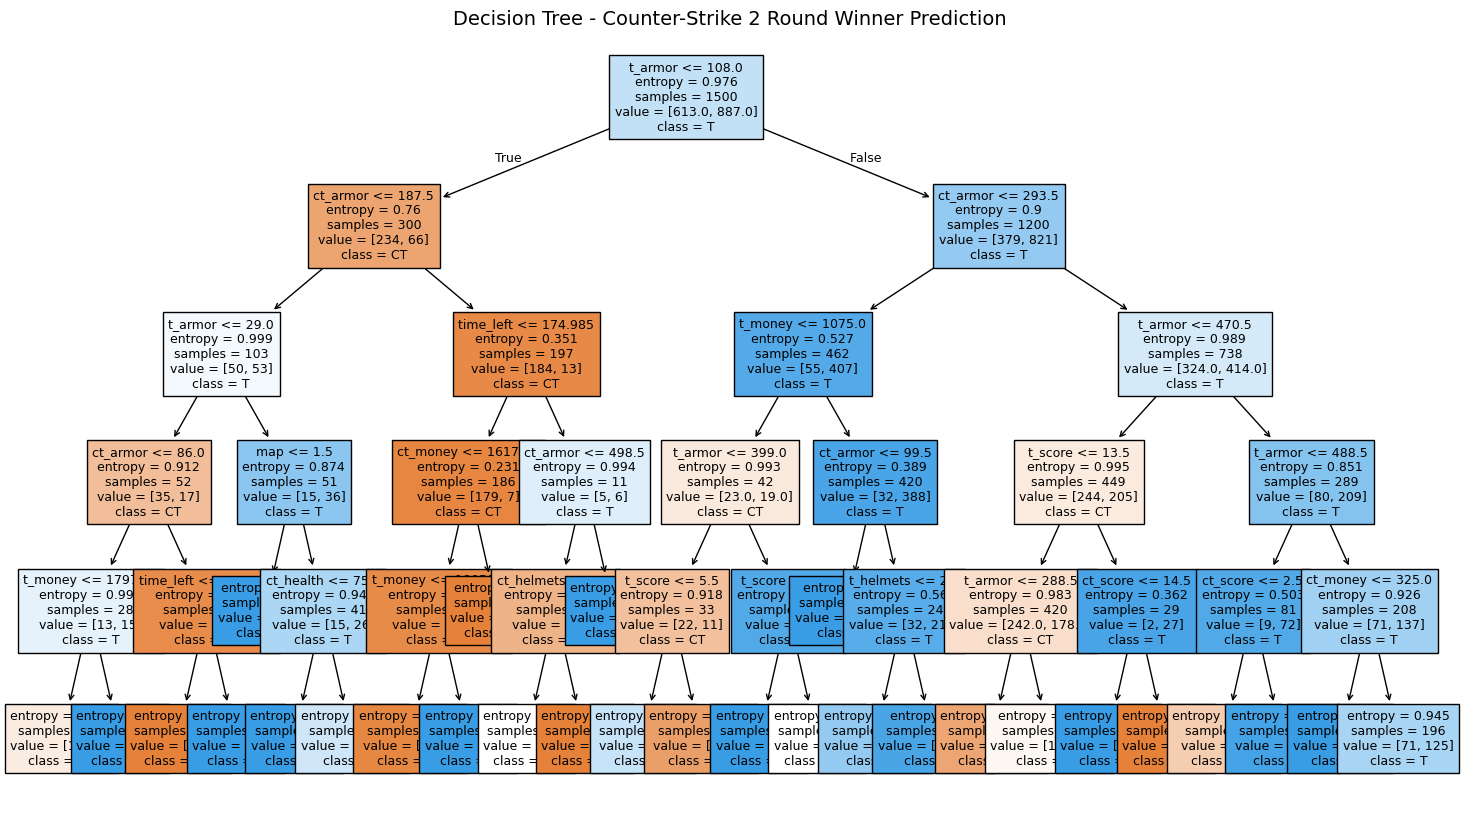

In [5]:
#202431140
X = df.drop(['round_winner'], axis=1) 
y = df['round_winner'] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

classifier = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=0) 
classifier.fit(X_train, y_train) 

plt.subplots(figsize=(18, 10)) 
tree.plot_tree(classifier, feature_names=X.columns, class_names=le_target.classes_, filled=True, fontsize=9) 
plt.title("Decision Tree - Counter-Strike 2 Round Winner Prediction", fontsize=14)
plt.show()

In [6]:
#202431140
y_pred = classifier.predict(X_test) 
akurasi = accuracy_score(y_test, y_pred) 
print(f"\nAkurasi Model: {akurasi:.4f} ({akurasi * 100:.2f}%)")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le_target.classes_))


Akurasi Model: 0.7120 (71.20%)

Confusion Matrix:
[[152  59]
 [ 85 204]]

Classification Report:
              precision    recall  f1-score   support

          CT       0.64      0.72      0.68       211
           T       0.78      0.71      0.74       289

    accuracy                           0.71       500
   macro avg       0.71      0.71      0.71       500
weighted avg       0.72      0.71      0.71       500



In [7]:
#202431140
sample_data = [[150.0, 0.0, 0.0, 0, 0, 500.0, 500.0, 400.0, 300.0, 5000.0, 4500.0, 1.0, 1.0]]
pred_numeric = classifier.predict(sample_data) 
pred_label = le_target.inverse_transform(pred_numeric)
print(f"\nHasil Prediksi Sampel Baru: {pred_numeric[0]} ({pred_label[0]})")


Hasil Prediksi Sampel Baru: 0 (CT)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# KNN

In [8]:
#202431140
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

df_knn = df.copy()
df_knn = pd.get_dummies(df_knn, drop_first=True)

X_knn = df_knn.drop(['round_winner'], axis=1, errors='ignore')
y_knn = le_target.fit_transform(df_knn['round_winner']) 

X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(
    X_knn, y_knn, test_size=0.25, random_state=0
)

In [9]:
#202431140
scaler = StandardScaler()
scaler.fit(X_train_knn)
X_train_scaled = scaler.transform(X_train_knn)
X_test_scaled = scaler.transform(X_test_knn)

In [10]:
#202431140
K_DEFAULT = 7
knn_clf = KNeighborsClassifier(n_neighbors=K_DEFAULT)
knn_clf.fit(X_train_scaled, y_train_knn)

y_pred_knn = knn_clf.predict(X_test_scaled)
acc_knn = accuracy_score(y_test_knn, y_pred_knn)
print(f"\nAkurasi Model KNN (K={K_DEFAULT}) dengan Scaling: {acc_knn:.4f} ({acc_knn * 100:.2f}%)")


Akurasi Model KNN (K=7) dengan Scaling: 0.8240 (82.40%)


In [11]:
#202431140
k_values = range(1, 20)
accuracies = []

for k in k_values:
    model_knn_loop = KNeighborsClassifier(n_neighbors=k)
    model_knn_loop.fit(X_train_scaled, y_train_knn)
    y_pred_loop = model_knn_loop.predict(X_test_scaled)
    acc = accuracy_score(y_test_knn, y_pred_loop)
    accuracies.append(acc)

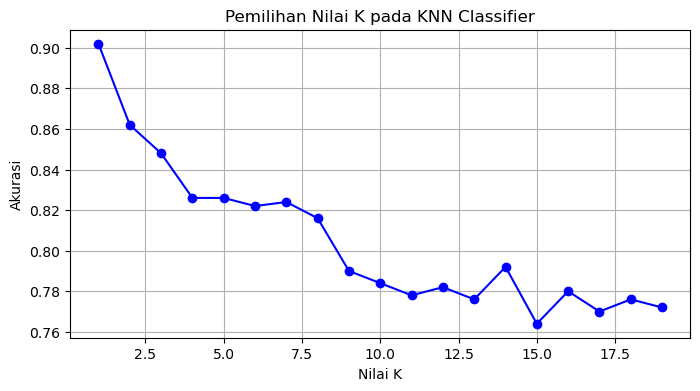

In [12]:
#202431140
plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b')
plt.xlabel("Nilai K")
plt.ylabel("Akurasi")
plt.title("Pemilihan Nilai K pada KNN Classifier")
plt.grid(True)
plt.show()